# exfildns — méthodologie d'apprentissage

Détection par machine learning des requêtes DNS servant à **exfiltrer des données** (DNS tunneling).

**Problématique.** Le DNS est presque toujours autorisé en sortie d'un réseau : un attaquant peut y
cacher des données en les encodant dans des noms de domaine
(`<morceau>.<données encodées>.domaine-attaquant.com`) que le résolveur relaie jusqu'à son serveur.
Peut-on reconnaître ces requêtes **une par une**, à partir du seul nom demandé, pour les détecter
en direct sur un réseau ?

Ce notebook déroule la méthode : données, features, découpage, puis apprentissage et performances.
Il **importe** le paquet `exfildns` au lieu de recopier son code : les fonctions montrées ici sont
exactement celles de l'application déployée.

> Dataset : **CIC-Bell-DNS-EXF-2021** (Canadian Institute for Cybersecurity).
> Mahdavifar, S., et al. *Lightweight Hybrid Detection of Data Exfiltration using DNS based on
> Machine Learning*. ICCNS 2021.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from exfildns.dataset import IP_ATTAQUANT, load_dataset
from exfildns.features import FEATURES, LONGUEUR_MAX, extract_features
from exfildns.model import CAPTURES_TEST, split_par_capture

pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.dpi"] = 90
DONNEES = "../data"  # dossier contenant Attacks/ et Benign/ (non versionné)

## 1. Le dataset

Le dataset fournit des CSV de features (« light ») et des captures réseau PCAP (« heavy »).
**Les CSV light ne contiennent pas d'exfiltration visible** : 99,94 % des lignes d'attaque sont
identiques à des lignes bénignes, ce n'est que le trafic de fond du poste
(détails dans `docs/donnees.md`). Un modèle entraîné dessus apprendrait un artefact.

On utilise donc les **9 PCAP heavy** (6 captures pendant une exfiltration, une par type de fichier
volé : audio, compressé, exécutable, image, texte, vidéo ; 3 captures de trafic normal), et on
calcule **nos propres features**, avec le même code que l'application.

**Étiquetage par requête** (et non par fichier) :
- `1` (exfiltration) : requête d'une capture d'attaque envoyée au serveur DNS de l'attaquant ;
- `0` (bénin) : requêtes des captures bénignes, et trafic de fond des captures d'attaque
  (envoyé à `8.8.8.8`).

In [2]:
df = load_dataset(DONNEES)  # ~1 min 30 la première fois, puis cache data/requetes.csv
print(f"{len(df)} requêtes, serveur de l'attaquant : {IP_ATTAQUANT}")
df.head()

290196 requêtes, serveur de l'attaquant : 192.168.20.72


,capture,dst,qname,label,FQDN_count,upper,lower,numeric,special,entropy,labels,labels_max,labels_average
0,heavy_audio,192.168.20.72,init.KNUGC2CNMFTWQ43POVSC43LQGN6DGOBQGY3Q,1,40,28,4,7,1,4.496439,2,35,19.5
1,heavy_audio,192.168.20.72,0.J4HgHlgzQH6j0ZYg822fnjet1rH6nhslzKFceUM,1,40,11,19,9,1,4.603056,2,38,19.5
2,heavy_audio,192.168.20.72,1.LnheqmgMMsjhGvJKHSCpGOG1P3b4l7zK1AkVq5N,1,40,16,16,7,1,4.884184,2,38,19.5
3,heavy_audio,192.168.20.72,2.VpHScRdmpxgPHhmb_o5PfNzxgn1rOB1OYfh1NQ5,1,40,14,19,5,2,4.703056,2,38,19.5
4,heavy_audio,192.168.20.72,3.eVnWrTk3RqyHuMo-Lv8QiPUHzf3ZE6sor-1eaNx,1,40,14,17,6,3,4.953056,2,38,19.5


In [3]:
par_capture = df.pivot_table(
    index="capture", columns="label", values="qname", aggfunc="count", fill_value=0
).rename(columns={0: "bénignes", 1: "exfiltration"})
par_capture

label,bénignes,exfiltration
capture,,
benign_heavy_1,23127,0
benign_heavy_2,18187,0
benign_heavy_3,25235,0
heavy_audio,103,38068
heavy_compressed,104,30568
heavy_exe,118,40539
heavy_image,94,41987
heavy_text,235,26907
heavy_video,144,44780


Chaque capture d'attaque contient aussi un peu de trafic normal (étiqueté 0) : le modèle ne peut
donc pas se contenter de reconnaître « la capture » d'où vient une requête.

Exemples de noms de chaque classe :

In [4]:
exemples = pd.concat(
    [
        df[df["label"] == 0].sample(5, random_state=0),
        df[df["label"] == 1].sample(5, random_state=0),
    ]
)
exemples[["capture", "dst", "qname", "label"]]

,capture,dst,qname,label
266634,benign_heavy_3,8.8.8.8,botrygg.se,0
235404,benign_heavy_1,8.8.8.8,my157p.com,0
276844,benign_heavy_3,8.8.8.8,gobento.no,0
227957,benign_heavy_1,8.8.8.8,suzuki.cz,0
257660,benign_heavy_2,8.8.8.8,factoring.ltd,0
83708,heavy_exe,192.168.20.72,14838.h1_jHo1xTi3REyGmaNGeiEJsBcZ-XmhaCZj,1
204409,heavy_video,192.168.20.72,25568.oLJ1pYGMuXkPQUrBGeDbGikVPKOqI9oquof,1
45421,heavy_compressed,192.168.20.72,7234.c0fKU_SoBGNN3gq6fxZz9Cxxe5CjrWe9LmKu,1
30392,heavy_audio,192.168.20.72,30317.54q4Y28IyyoVQxIRReMG-tO89o486MRRHGA,1
42570,heavy_compressed,192.168.20.72,4388.bkvsifDg2nVScNmnZhLrNfEZ_BzMA4BNFU1o,1


Les exfiltrations ont la forme produite par l'outil du dataset (DNSExfiltrator) :
un numéro de morceau puis des données encodées en base64 (en base32 pour le message
d'initialisation `init.`), longues et sans mots lisibles.

### Déséquilibre des classes

Le dataset **inverse** la proportion réelle : sur un vrai réseau, l'exfiltration est rare.
C'est pour cela qu'on ne jugera pas le modèle sur l'accuracy (partie 2).

label
bénin           0.232
exfiltration    0.768
Name: count, dtype: float64


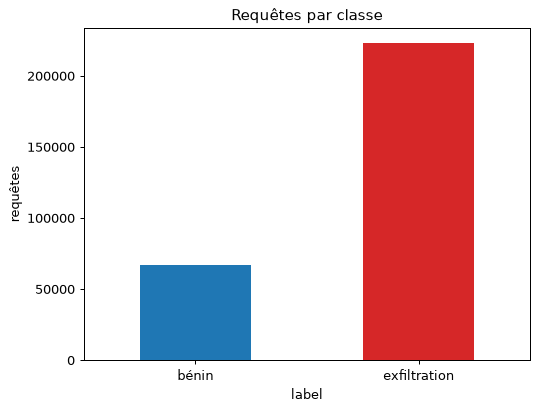

In [5]:
repartition = df["label"].map({0: "bénin", 1: "exfiltration"}).value_counts().sort_index()
print((repartition / len(df)).round(3))
repartition.plot.bar(title="Requêtes par classe", rot=0, color=["tab:blue", "tab:red"])
plt.ylabel("requêtes")
plt.show()

## 2. Un piège : les paquets tronqués

Les captures ont été enregistrées en ne gardant que les **96 premiers octets** de chaque paquet.
Il ne reste qu'une quarantaine de caractères du nom : **100 %** des noms d'exfiltration atteignent
40 caractères, contre **0,05 %** des noms bénins.

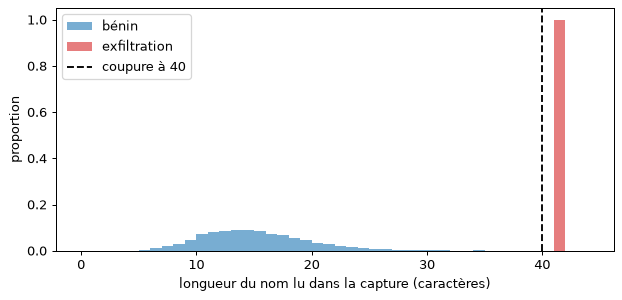

In [6]:
longueur = df["qname"].str.len()
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, nom, couleur in ((0, "bénin", "tab:blue"), (1, "exfiltration", "tab:red")):
    longueur[df["label"] == label].plot.hist(
        bins=range(0, 45), alpha=0.6, density=True, label=nom, color=couleur, ax=ax
    )
ax.axvline(LONGUEUR_MAX, color="black", linestyle="--", label=f"coupure à {LONGUEUR_MAX}")
ax.set_xlabel("longueur du nom lu dans la capture (caractères)")
ax.set_ylabel("proportion")
ax.legend()
plt.show()

Si on calculait les features sur les noms bruts, le modèle risquerait d'apprendre
« nom coupé = exfiltration », un artefact de la capture qui n'existe pas sur un vrai réseau.
**Parade** : toutes les features sont calculées sur les **40 premiers caractères**
du nom (`LONGUEUR_MAX`), à l'entraînement comme en production.

## 3. Les features retenues

L'article définit 14 features *stateless* (calculées sur une seule requête) et 16 *stateful*
(calculées sur une fenêtre de requêtes). On garde **9 features stateless**, celles qui ne dépendent
que des caractères du nom, pour pouvoir juger **chaque requête dès qu'elle passe** :

| Feature | Signification |
|---|---|
| `FQDN_count` | nombre de caractères du nom |
| `upper`, `lower`, `numeric`, `special` | nombre de majuscules, minuscules, chiffres, autres caractères |
| `entropy` | entropie de Shannon des caractères (désordre du texte) |
| `labels` | nombre de parties séparées par des points |
| `labels_max`, `labels_average` | longueur du plus long label, longueur moyenne |

Écartées : `sld`, `subdomain`, `subdomain_length`, `len`, qui supposent de connaître le suffixe
public (`.com`, `.co.uk`…), jamais visible dans les noms d'exfiltration tronqués ; `longest_word`,
qui demande un dictionnaire.

La même fonction `extract_features` sert à l'entraînement et à l'inférence :

In [7]:
benin = df.loc[df["label"] == 0, "qname"].iloc[0]
exfil = df.loc[df["label"] == 1, "qname"].iloc[0]
pd.DataFrame({benin: extract_features(benin), exfil: extract_features(exfil)}).round(2)

,dns.google,init.KNUGC2CNMFTWQ43POVSC43LQGN6DGOBQGY3Q
FQDN_count,10.00,40.0
upper,0.00,28.0
lower,9.00,4.0
numeric,0.00,7.0
special,1.00,1.0
entropy,2.92,4.5
labels,2.00,2.0
labels_max,6.00,35.0
labels_average,4.50,19.5


### Distribution des features par classe

Chaque barre donne la part des requêtes de la classe qui tombent dans l'intervalle.

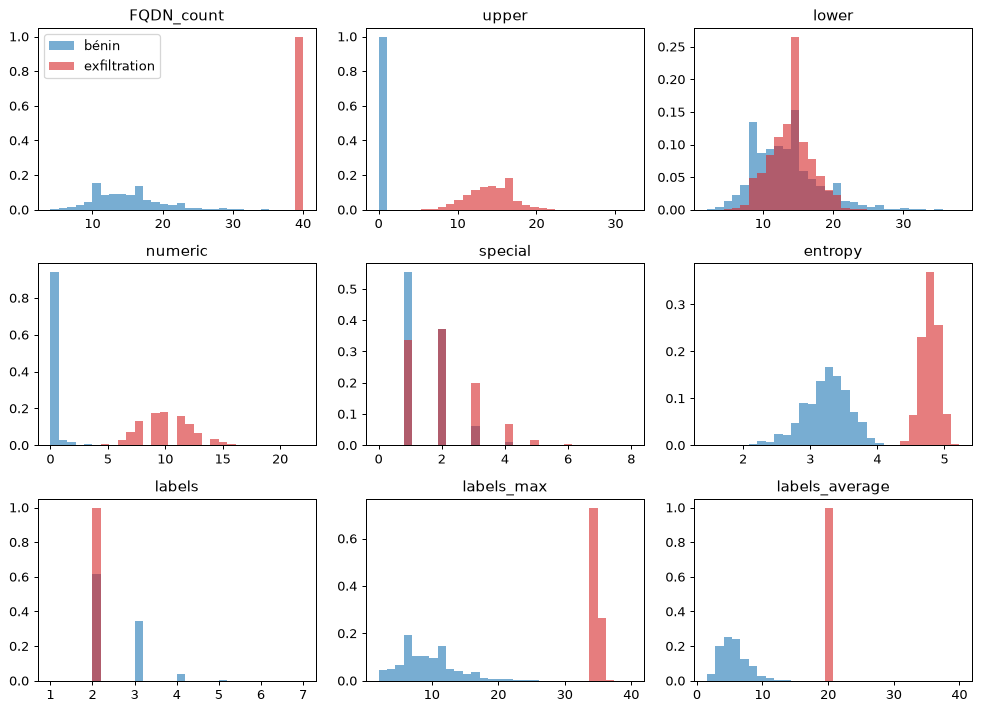

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for feature, ax in zip(FEATURES, axes.ravel(), strict=True):
    intervalles = np.histogram_bin_edges(df[feature], bins=30)  # communs aux deux classes
    for label, nom, couleur in ((0, "bénin", "tab:blue"), (1, "exfiltration", "tab:red")):
        valeurs = df.loc[df["label"] == label, feature]
        poids = np.full(len(valeurs), 1 / len(valeurs))  # proportion de la classe
        ax.hist(valeurs, bins=intervalles, weights=poids, alpha=0.6, label=nom, color=couleur)
    ax.set_title(feature)
axes[0, 0].legend()
fig.tight_layout()
plt.show()

In [9]:
df.groupby("label")[FEATURES].median().rename(index={0: "bénin", 1: "exfiltration"}).round(2)

,FQDN_count,upper,lower,numeric,special,entropy,labels,labels_max,labels_average
label,,,,,,,,,
bénin,14.0,0.0,13.0,0.0,1.0,3.28,2.0,9.0,5.5
exfiltration,40.0,14.0,14.0,10.0,2.0,4.78,2.0,34.0,19.5


Les deux classes sont très séparées : les noms d'exfiltration sont longs, riches en majuscules
et en chiffres, à forte entropie, avec un très long label (les données encodées).
La tâche est donc **facile sur ce dataset**, et les scores seront très élevés : il faudra le dire
et vérifier le modèle sur du trafic réel.

Deux limites à garder en tête pour le déploiement :
- **aucun nom bénin ne contient de majuscule** (domaines populaires en minuscules), alors que le
  base64 en est plein : un outil qui encode en minuscules (hexadécimal, base32) n'aurait pas cet
  indice, et seuls la longueur, le très long label, les chiffres et l'entropie le trahiraient ;
- les noms bénins sont courts ; un vrai réseau a des noms longs et aléatoires légitimes
  (CDN, services cloud), source possible de faux positifs.

## 4. Découpage entraînement / test

Les requêtes d'une même capture se ressemblent énormément (même fichier exfiltré, même session de
navigation). Un tirage aléatoire 70/30, comme dans l'article, mettrait des quasi-doublons des deux
côtés et surestimerait les performances.

On met donc de côté des **captures entières** pour le test : `heavy_video` (une exfiltration
d'un type de fichier jamais vu à l'entraînement) et `benign_heavy_3` (une session de navigation
jamais vue).

In [10]:
train, test = split_par_capture(df, CAPTURES_TEST)
resume = pd.DataFrame(
    {
        "requêtes": [len(train), len(test)],
        "part du total": [len(train) / len(df), len(test) / len(df)],
        "part d'exfiltration": [train["label"].mean(), test["label"].mean()],
    },
    index=["entraînement", "test"],
).round(3)
resume

,requêtes,part du total,part d'exfiltration
entraînement,220037,0.758,0.809
test,70159,0.242,0.638


Environ 24 % des requêtes servent au test. La part d'exfiltration y est plus faible qu'à
l'entraînement (64 % contre 81 %) : c'est sans gravité, puisque les métriques retenues (rappel,
taux de faux positifs) se calculent classe par classe.
Le jeu de test n'est **jamais** utilisé pour choisir le modèle ni le seuil : il sert uniquement à
mesurer les performances finales (partie 2).